<a href="https://colab.research.google.com/github/simranvikram1407-cpu/parkinsons-eeg-beta-analysis/blob/main/parkinsons_beta_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mne openneuro-py


In [2]:
import openneuro as on

on.download(
    dataset="ds002778",
    target_dir="ds002778",
    include=["sub-hc1"]
)

🌍 Preparing to download ds002778 …
📥 Checking 12 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds002778 (downloaded 12 files and 11.6 MB).


In [3]:
from pathlib import Path

files = list(
    Path("ds002778").glob(
        "sub-hc1/**/eeg/*_eeg.bdf"
    )
)

print(files)

[PosixPath('ds002778/sub-hc1/ses-hc/eeg/sub-hc1_ses-hc_task-rest_eeg.bdf')]


In [4]:
import mne

mne.set_log_level("WARNING")

raw = mne.io.read_raw_bdf(
    str(files[0]),
    preload=True
)

print(raw)

<RawBDF | sub-hc1_ses-hc_task-rest_eeg.bdf, 41 x 98304 (192.0 s), ~30.8 MiB, data loaded>


In [5]:
print("Channel names:")
print(raw.ch_names)

print("\nSampling frequency:")
print(raw.info["sfreq"])

print("\nChannel types:")
print(raw.get_channel_types())

Channel names:
['Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5', 'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3', 'Pz', 'PO3', 'O1', 'Oz', 'O2', 'PO4', 'P4', 'P8', 'CP6', 'CP2', 'C4', 'T8', 'FC6', 'FC2', 'F4', 'F8', 'AF4', 'Fp2', 'Fz', 'Cz', 'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'Status']

Sampling frequency:
512.0

Channel types:
['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'stim']


In [6]:
# Make a copy of the original recording
raw_eeg = raw.copy()

# Keep the 32 named scalp EEG electrodes
scalp_channels = [
    'Fp1', 'AF3', 'F7', 'F3', 'FC1', 'FC5',
    'T7', 'C3', 'CP1', 'CP5', 'P7', 'P3',
    'Pz', 'PO3', 'O1', 'Oz', 'O2', 'PO4',
    'P4', 'P8', 'CP6', 'CP2', 'C4', 'T8',
    'FC6', 'FC2', 'F4', 'F8', 'AF4', 'Fp2',
    'Fz', 'Cz'
]

raw_eeg.pick(scalp_channels)

print(raw_eeg)
print("Number of selected channels:", len(raw_eeg.ch_names))

<RawBDF | sub-hc1_ses-hc_task-rest_eeg.bdf, 32 x 98304 (192.0 s), ~24.0 MiB, data loaded>
Number of selected channels: 32


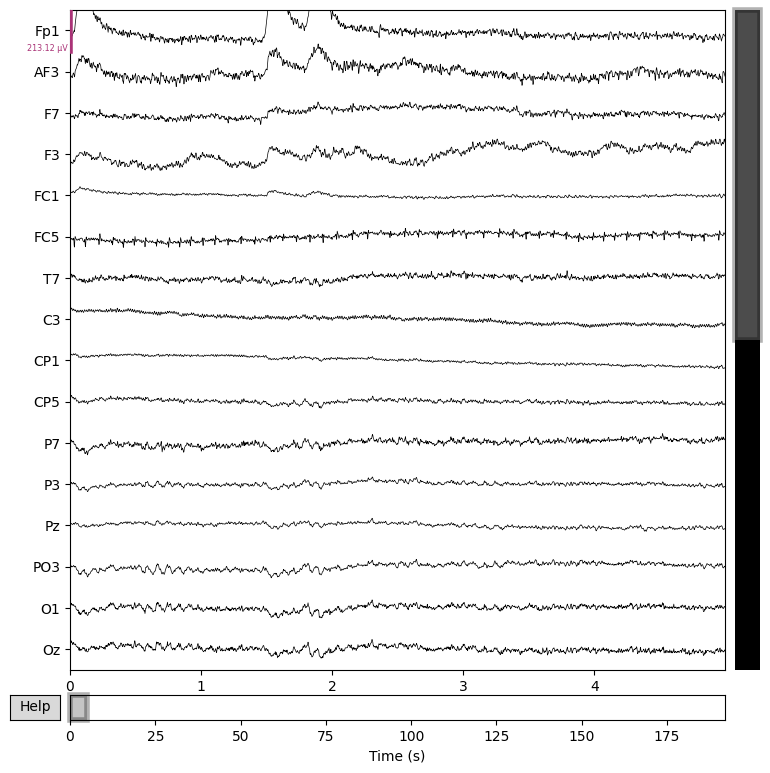

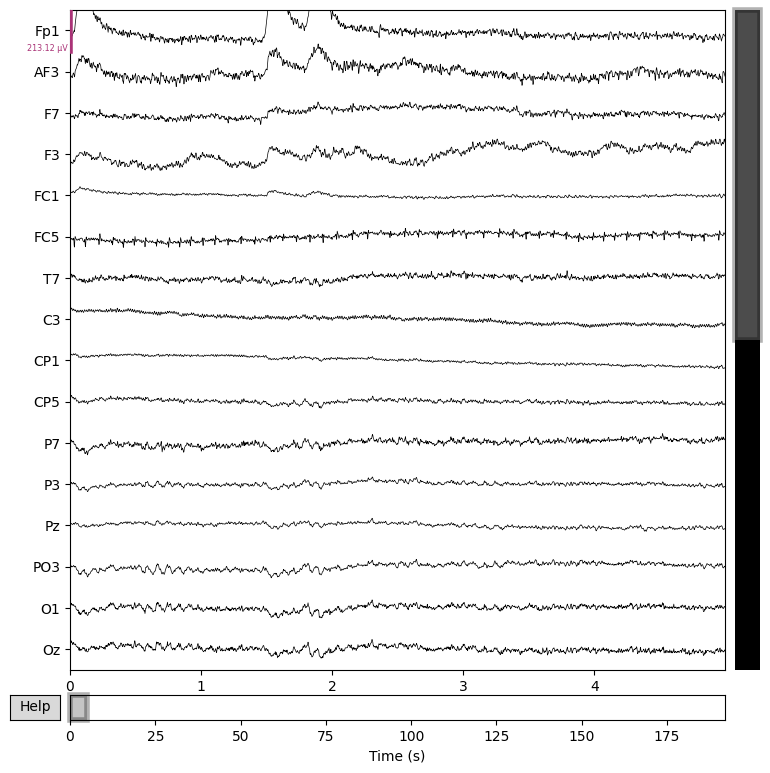

In [7]:
raw_eeg.plot(
    duration=5,      #display 5 seconds of the recording
    n_channels=16,    #display 16 channels at a time
    scalings="auto"   #MNE chooses display scaling so the traces are easier to view
)

In [8]:
# Make another copy so the unfiltered data stays available
#This is preliminary filtering step, not complete artifact removal
raw_filtered = raw_eeg.copy()

# Apply a 1–45 Hz band-pass filter
raw_filtered.filter(   #sets the upper filter cutoff to 45 Hz.
    l_freq=1.0,        #sets the lower filter cutoff to 1 Hz.
    h_freq=45.0        #sets the upper filter cutoff to 45 Hz.
)

print(raw_filtered)

<RawBDF | sub-hc1_ses-hc_task-rest_eeg.bdf, 32 x 98304 (192.0 s), ~24.0 MiB, data loaded>


In [9]:
# Calculate the power spectrum using Welch's method
psd = raw_filtered.compute_psd(
    method="welch",
    fmin=1,
    fmax=45,
    n_fft=2048
)

# Extract the power values and corresponding frequencies
power = psd.get_data()
frequencies = psd.freqs

print("Power array shape:", power.shape)
print("Frequency range:", frequencies[0], "to", frequencies[-1], "Hz")

Power array shape: (32, 177)
Frequency range: 1.0 to 45.0 Hz
